<h1><center>CM4X-p25 vs CM4X-p125<br>Leading-Order BV Balances of the HAC10 Regimes<br><small>Kaiser et al. (2022) dominant-balance analysis</small></center></h1>

| Scenario | BVB terms | Regimes | Entropy | 
|---|---|---|---|
| **p25** (eddy-permitting, 1/4°) | `inputs/global_CM4X_p25_BVB_tm_fields.zarr` | `inputs/nn_labels_HAC10_emb_ID17_CM4X_p25_tm.zarr` | `inputs/entropy_HAC10_emb_ID17_CM4X_p25_tm.zarr` |
| **p125** (eddy-resolving, 1/8°) | `inputs/global_CM4X_p125_BVB_tm_fields.zarr`| `inputs/nn_labels_HAC10_emb_ID19_CM4X_p125_tm.zarr`| `inputs/entropy_HAC10_emb_ID19_CM4X_p125_tm.zarr`|



# Method recap: Kaiser et al. (2022)

To Be Added


# Set up Requirements

## Import Python libraries



In [1]:
#!/usr/bin/env python3
import os
import sys
import xarray as xr
import numpy as np
import pandas as pd
import seaborn as sns
import time
import copy
import calendar
import xesmf as xe

import matplotlib as mpl
import matplotlib.path as mpath
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
from matplotlib.colors import ListedColormap, BoundaryNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LongitudeFormatter, LatitudeFormatter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

from shapely.geometry import Polygon
import cartopy.io.shapereader as shpreader
from cartopy.feature import ShapelyFeature
from collections import Counter
import glasbey
from matplotlib.colors import to_hex

import matplotlib.cm as cm
from cmocean import cm as cmo
from sklearn.metrics import silhouette_score, silhouette_samples
from cartopy.feature import ShapelyFeature

import zarr
import numcodecs
from scipy.stats import mode
from dask.diagnostics import ProgressBar

import argparse
import logging
from pathlib import Path

logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s  %(levelname)s  %(message)s",
                    datefmt="%H:%M:%S",)
log = logging.getLogger(__name__)

plt.rcParams["font.family"] = "DejaVu Sans"

## Set up customized libraries

### Plotting

In [2]:
from string import ascii_lowercase as asci

def number_figures(axes, pos=None, labels=asci, braces=True, **text_kwargs):

    depth = lambda L: isinstance(L, list) and max(map(depth, L)) + 1

    if pos is None:
        pos = [[0.99, 0.93]] * len(axes)
    elif (depth(pos) == 1) & (len(pos) == 2):
        pos = [list(pos)] * len(axes)
    elif (depth(pos) != 2) & (len(pos) != len(axes)):
        raise (Exception, 'check the position is the right format')
    
    for c, ax in enumerate(axes):
        x0, x1 = ax.get_xlim()
        y0, y1 = ax.get_ylim()

        w = x1 - x0
        h = y1 - y0
        x = x0 + w * pos[c][0]
        y = y0 + h * pos[c][1]

        t = '%s' % labels[c]
        if braces:
            t = '(%s)' % (t)
        ax.text(x, y, t, **text_kwargs)
          

def add_map_features(ax, draw_countries=False, draw_labels=False, right=False):
    # Add coastlines
    ax.coastlines(color="lightgrey", linewidth=0.1125)

    # Add land and states
    ax.add_feature(cfeature.LAND, facecolor='darkgrey', edgecolor='lightgrey', linewidth=0.15, zorder=-1)
    if draw_countries:
        ax.add_feature(cfeature.BORDERS, linewidth=0.125, alpha=0.25, edgecolor='black')
    
    # Create gridlines and specify the coordinate system
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=draw_labels,
                      linewidth=0.5, color='black', alpha=0.25, linestyle='--', x_inline=False, y_inline=False)
    
    if draw_labels:
        # Customize the labels format
        gl.xformatter = LongitudeFormatter()
        gl.yformatter = LatitudeFormatter()
        
        # Optional: Customize label appearance
        gl.xlabel_style = {'size': 8, 'color': 'black'}
        gl.ylabel_style = {'size': 8, 'color': 'black'}
        
        # Remove default labels on the top and right sides
        gl.top_labels = False
        gl.right_labels = right


def add_grid_borders(ax, land=False, borders=True, draw_labels=True, right=False):
    # Create gridlines and specify the coordinate system
    gl = ax.gridlines(crs=ccrs.PlateCarree(), dms=True, draw_labels=draw_labels,
                      linewidth=0.15, color='black', alpha=0.25, linestyle='--')
    if land:
        ax.add_feature(cfeature.LAND, facecolor='darkgrey', edgecolor='lightgrey', linewidth=0.15, zorder=-1)
        
    if borders:
        ax.add_feature(cfeature.BORDERS, linewidth=0.125, alpha=0.25, edgecolor='black')
    
    if draw_labels:
        # Customize the labels format
        gl.xformatter = LongitudeFormatter()
        gl.yformatter = LatitudeFormatter()
        
        # Optional: Customize label appearance
        gl.xlabel_style = {'size': 8, 'color': 'black'}
        gl.ylabel_style = {'size': 8, 'color': 'black'}
        
        # Remove default labels on the top and right sides
        gl.top_labels = False
        gl.right_labels = right



### Function to calculate dominant balance 

In [3]:
# Add local module to the path
import os
import sys
source = os.path.abspath('/home/djeutsch/Projects/seaLevelRegimes')
if source not in sys.path:
    sys.path.append(source)

# Import local modules
from kaiserbalance import kaiser_balance as kbal


In [4]:
# Set up the base directory
BASE_DIR = "/group/maikesgrp/laique/SLVP"

bvb_terms = ['beta_V', 'BPT','Curl_Adv', 'Curl_taus','Curl_taub','Curl_diff', 'Mass_flux', 'eta_dt', 'Curl_dudt']
max_r = [4.1e-10, 4.1e-10, 4.1e-10, 2.1e-10, 2.1e-10, 2.1e-10, 4.1e-12, 1.1e-14, 1.1e-11]
labels = [r'$\beta \, \overline{V}$', r'$\overline{J(p_b, H)}/\rho_o$', 
          r'$\hat{\mathbf{z}} \cdot (\nabla \wedge \overline{\mathcal{A}})$',
          r'$\hat{\mathbf{z}} \cdot (\nabla \wedge\overline{{\tau_s}})/\rho_o$', 
          r'$\hat{\mathbf{z}} \cdot (-\nabla \wedge\overline{{\tau_b}})/\rho_o$',
          r'$\hat{\mathbf{z}} \cdot (\nabla \wedge \overline{\mathcal{B}})$', 
          r'$-f \, \overline{Q}_m/{\rho_o}$', r'$f \, \partial_t\overline{\eta}$',
          r'$\hat{\mathbf{z}} \cdot (-\nabla \wedge \overline{\mathcal{U}_t})$']
bvb_terms

['beta_V',
 'BPT',
 'Curl_Adv',
 'Curl_taus',
 'Curl_taub',
 'Curl_diff',
 'Mass_flux',
 'eta_dt',
 'Curl_dudt']

# CM4X BVB Regimes and Leading Order Balance 

## Load the required datasets

In [5]:
nc = 10
data_res = "p25"
path_bvb = f"{BASE_DIR}/inputs/global_CM4X_{data_res}_BVB_tm_fields.zarr"
path_lbs = f"{BASE_DIR}/inputs/nn_labels_HAC10_emb_ID17_CM4X_{data_res}_tm.zarr"
path_ent = f"{BASE_DIR}/inputs/entropy_HAC10_emb_ID17_CM4X_{data_res}_tm.zarr"
ds_bvb = xr.open_zarr(path_bvb, chunks=None)
nemi_labels = xr.open_zarr(path_lbs, chunks=None).bvb_regime.copy()
da_ent = xr.open_zarr(path_ent, chunks=None).entropy.copy()

nemi_labels

<xarray.DataArray 'bvb_regime' (lat: 1080, lon: 1440)> Size: 6MB
[1555200 values with dtype=float32]
Coordinates:
  * lat      (lat) float64 9kB -89.92 -89.75 -89.58 -89.42 ... 89.58 89.75 89.92
  * lon      (lon) float64 12kB -179.9 -179.6 -179.4 ... 179.4 179.6 179.9
Attributes:
    Description:    Identified Regimes from a HAC-based NEMI approach from st...
    standard_name:  Geographically projected regimes

## With gridspec

In [31]:
import matplotlib.gridspec as gridspec
import matplotlib.dates as mdates    
import matplotlib.patches as patches
import string

In [32]:
import scipy.stats

def _mode(*args, **kwargs):
    return scipy.stats.mode(*args, **kwargs).mode.squeeze()

def mode(obj, dim=None):
    assert isinstance(obj, xr.DataArray)

    return xr.apply_ufunc(
        _mode,
        obj,
        input_core_dims=[[dim]],
        kwargs={"axis": -1, "nan_policy": "omit", "keepdims": False},
        output_dtypes=[obj.dtype],)

In [33]:
N = 10
quantile = 1
nf = len(bvb_terms)
percent_cutoff = None
df_magnitudes, df_dominant_balance = kbal.dominant_balance(ds_bvb, nemi_labels, da_ent, nf=nf, 
                                                           qt=quantile, percent_cutoff=percent_cutoff, bias_flag='unbiased')
# nemi_labels = kbal.mode(nemi_labels)
nemi_labels

<xarray.DataArray 'bvb_regime' (lat: 1080, lon: 1440)> Size: 6MB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [ 5.,  5.,  5., ...,  5.,  5.,  5.],
       [ 5.,  5.,  5., ...,  5.,  5.,  5.],
       [ 5.,  5.,  5., ...,  5.,  5.,  5.]], shape=(1080, 1440), dtype=float32)
Coordinates:
  * lat      (lat) float64 9kB -89.92 -89.75 -89.58 -89.42 ... 89.58 89.75 89.92
  * lon      (lon) float64 12kB -179.9 -179.6 -179.4 ... 179.4 179.6 179.9
Attributes:
    Description:    Identified Regimes from a HAC-based NEMI approach from st...
    standard_name:  Geographically projected regimes

20:21:22  INFO  Substituting symbol A from STIXNonUnicode
20:21:22  INFO  Substituting symbol B from STIXNonUnicode
20:21:29  INFO  Substituting symbol A from STIXNonUnicode
20:21:29  INFO  Substituting symbol B from STIXNonUnicode


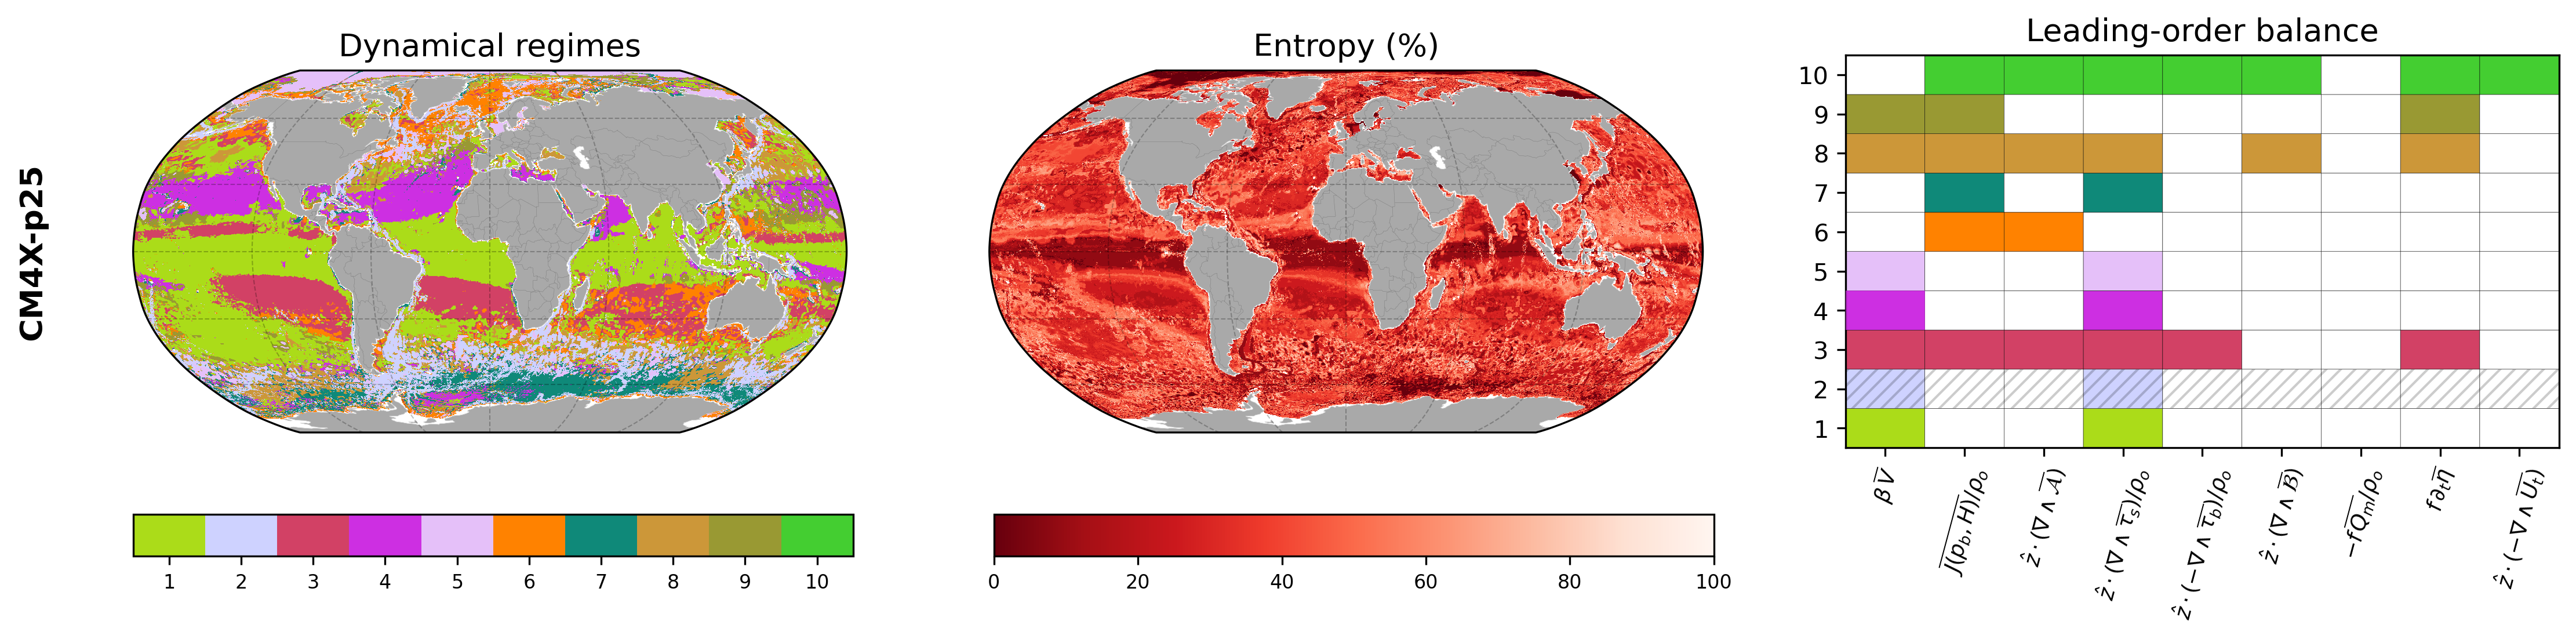

In [58]:
#  Configuration 
lw = 0.125
nc = 10
N = len(np.unique(nemi_labels.values[np.isfinite(nemi_labels.values)]))
colors = ["#abdc19", "#ced2ff", "#D24165", "#CD2FE2", "#e5c0f9ff",
          "#ff8200", "#0F8979", "#CC9739", "#999933", "#44CE31",]
cmap = ListedColormap(colors, name="cluster_cmap")
label_bounds = np.arange(0.5, N + 1.5, 1)
label_norm = mcolors.BoundaryNorm(label_bounds, cmap.N, clip=True)

# Prepare data 
da = nemi_labels
df = df_dominant_balance.copy()

# Ensure the balance table has exactly N rows
df = df.reindex(range(N))
mask = df.to_numpy()
matrix = np.where(mask == 1, np.arange(1, N + 1)[:, None], 0)

matrix_cmap = ListedColormap(["white"] + [to_hex(c) for c in cmap.colors])
matrix_bounds = np.arange(-0.5, N + 1.5, 1)
matrix_norm = mcolors.BoundaryNorm(matrix_bounds, matrix_cmap.N)

# Figure and panels 
fig = plt.figure(figsize=(18, 8), dpi=300)
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.6])

ax1 = fig.add_subplot(gs[0, 0], projection=ccrs.Robinson())
ax2 = fig.add_subplot(gs[0, 1], projection=ccrs.Robinson())
ax3 = fig.add_subplot(gs[0, 2])

# Dynamical regimes
cf1 = da.plot(ax=ax1, transform=ccrs.PlateCarree(), cmap=cmap, norm=label_norm, add_colorbar=False,)

# Entropy
cf2 = da_ent.plot(ax=ax2, vmin=0., vmax=100., transform=ccrs.PlateCarree(), cmap=plt.cm.Reds_r, add_colorbar=False,)

# Leading-order balance matrix
ax3.pcolor(matrix, cmap=matrix_cmap, norm=matrix_norm, edgecolors="k", linewidths=lw,)

# Highlight a selected cell
r, c = 3, 0
rect = patches.Rectangle((c, r), 1, 1, facecolor=colors[r], alpha=0.7, edgecolor="none", zorder=5,)
ax3.add_patch(rect)

# Highlight a range of cells with hatching
rect = patches.Rectangle((0, 1), 9, 1, fill=False, hatch="////", edgecolor="k", linewidth=0, alpha=0.2, zorder=3,)
ax3.add_patch(rect)

num_rows, num_cols = df.shape
ax3.set_yticks(np.arange(0.5, num_rows, 1))
ax3.set_yticklabels(range(1, num_rows + 1), size=10)
ax3.set_xticks(np.arange(0.5, num_cols + 0.5))
ax3.set_xticklabels(df.columns, size=9, rotation=75)

# Geographic gridlines
for ax in (ax1, ax2):
    add_map_features(ax=ax, draw_countries=True, right=False)

# Titles and panel labels
row_label = f"CM4X-{data_res}"

for ax, title, letter in zip((ax1, ax2, ax3), ("Dynamical regimes", "Entropy (%)", "Leading-order balance"), string.ascii_lowercase,):
    ax.set_title(f"{title}", fontsize=13)

ax1.text(-0.12, 0.5, row_label, transform=ax1.transAxes, ha="right", va="center", fontsize=13, weight="bold", rotation=90,)

# Colorbars 
fig.subplots_adjust(hspace=0.1)
cbar_ticks = np.arange(1, num_rows + 1)
cax1 = fig.add_axes([0.125, 0.52, 0.23, 0.03])
cbar1 = fig.colorbar(cf1, cax=cax1, orientation="horizontal", 
                     ticks=cbar_ticks, boundaries=label_bounds, extend="neither",)
cbar1.ax.tick_params(labelsize=8, which="minor", direction="in", length=0)
cbar1.set_ticklabels(list(range(1, num_rows + 1)), fontsize=8)

#
cax2 = fig.add_axes([0.4, 0.52, 0.23, 0.03])
cbar2 = fig.colorbar(cf2, cax=cax2, orientation="horizontal", extend="neither")
cbar2.ax.tick_params(labelsize=8)

#
# fig.savefig(f'{BASE_DIR}/figures/lead_order_balance_HAC10_emb_ID17_CM4X_{data_res}_tm.png', bbox_inches='tight',dpi=300)
# Dominant dynamical regimes and associated uncertainty across Isca